# 03.7 · ROC curves, AUC and choosing a threshold by business cost

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/07-roc-auc-threshold/lesson.ipynb)

Read the [README](README.md) and do the ten-customer table by hand first. This notebook checks every number, draws the curves, then applies the cost rule to the real ShopWave customers.

## 1. Ten scored customers

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

ten = pd.DataFrame({
    "customer": list("ABCDEFGHIJ"),
    "p":  [0.95, 0.85, 0.80, 0.70, 0.60, 0.55, 0.40, 0.30, 0.20, 0.10],
    "y":  [1, 1, 0, 1, 0, 1, 0, 1, 0, 0],
})
ten

,customer,p,y
0,A,0.95,1
1,B,0.85,1
2,C,0.80,0
3,D,0.70,1
4,E,0.60,0
5,F,0.55,1
6,G,0.40,0
7,H,0.30,1
8,I,0.20,0
9,J,0.10,0


## 2. Three thresholds by hand, then all of them

In [2]:
def counts(y, p, t):
    """TP, FP, FN, TN when flagging churn for p >= t."""
    y, pred = np.asarray(y), (np.asarray(p) >= t).astype(int)
    TP = int(((y == 1) & (pred == 1)).sum()); FP = int(((y == 0) & (pred == 1)).sum())
    FN = int(((y == 1) & (pred == 0)).sum()); TN = int(((y == 0) & (pred == 0)).sum())
    return TP, FP, FN, TN

def cost(y, p, t, c_voucher=5, c_lost=60):
    TP, FP, FN, TN = counts(y, p, t)
    return c_voucher * (TP + FP) + c_lost * FN

rows = []
for t in [0.90, 0.50, 0.25]:
    TP, FP, FN, TN = counts(ten["y"], ten["p"], t)
    rows.append(dict(t=t, TP=TP, FP=FP, FN=FN, TN=TN, TPR=TP/(TP+FN), FPR=FP/(FP+TN),
                     precision=TP/(TP+FP), cost=cost(ten["y"], ten["p"], t)))
pd.DataFrame(rows).set_index("t").round(2)

,TP,FP,FN,TN,TPR,FPR,precision,cost
t,,,,,,,,
0.90,1,0,4,5,0.2,0.0,1.00,245
0.50,4,2,1,3,0.8,0.4,0.67,90
0.25,5,3,0,2,1.0,0.6,0.62,40


Matches the README table: (FPR, TPR) = (0, 0.2), (0.4, 0.8), (0.6, 1.0), and costs £245, £90, £40.

`roc_curve` does this for *every* threshold at once (one per distinct score, plus a starting point).

In [3]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thr = roc_curve(ten["y"], ten["p"])
pd.DataFrame({"threshold": thr, "FPR": fpr, "TPR": tpr}).round(2)

,threshold,FPR,TPR
0,inf,0.0,0.0
1,0.95,0.0,0.2
2,0.85,0.0,0.4
3,0.80,0.2,0.4
4,0.70,0.2,0.6
5,0.60,0.4,0.6
6,0.55,0.4,0.8
7,0.40,0.6,0.8
8,0.30,0.6,1.0
9,0.10,1.0,1.0


## 3. AUC by counting pairs

In [4]:
churners = ten[ten["y"] == 1]["p"].values
stayers = ten[ten["y"] == 0]["p"].values
pairs_correct = sum((c > s) for c in churners for s in stayers)
print(f"{pairs_correct} of {len(churners) * len(stayers)} pairs ranked correctly → AUC = {pairs_correct / 25:.2f}")
print(f"sklearn roc_auc_score: {roc_auc_score(ten['y'], ten['p']):.2f}")

19 of 25 pairs ranked correctly → AUC = 0.76
sklearn roc_auc_score: 0.76


## 4. The curves

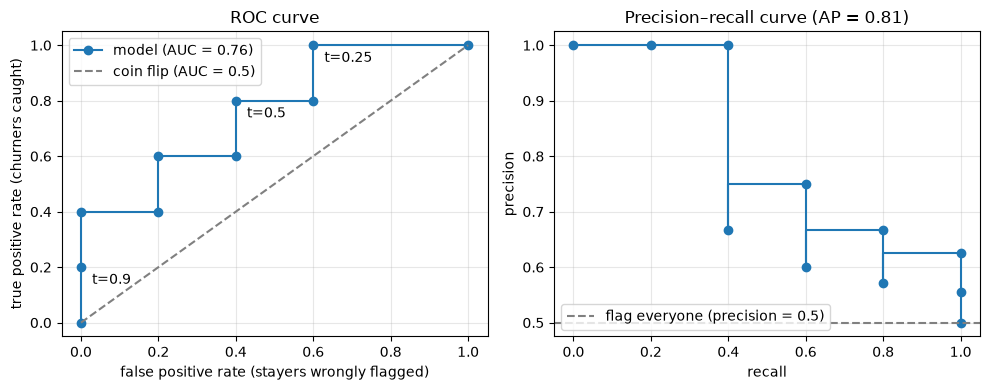

In [5]:
from sklearn.metrics import precision_recall_curve, average_precision_score
prec, rec, _ = precision_recall_curve(ten["y"], ten["p"])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(fpr, tpr, marker="o", label=f"model (AUC = {roc_auc_score(ten['y'], ten['p']):.2f})")
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="coin flip (AUC = 0.5)")
for t, x_, y_ in [(0.9, 0, .2), (0.5, .4, .8), (0.25, .6, 1)]:
    ax[0].annotate(f"t={t}", (x_, y_), textcoords="offset points", xytext=(8, -12))
ax[0].set(xlabel="false positive rate (stayers wrongly flagged)", ylabel="true positive rate (churners caught)", title="ROC curve")
ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].step(rec, prec, where="post", marker="o")
ax[1].axhline(ten["y"].mean(), ls="--", color="gray", label=f"flag everyone (precision = {ten['y'].mean():.1f})")
ax[1].set(xlabel="recall", ylabel="precision", title=f"Precision–recall curve (AP = {average_precision_score(ten['y'], ten['p']):.2f})")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

Left: the ROC curve, with your three hand-computed points labelled. Right: precision against recall; the dashed line is what you get by flagging everyone.

## 5. Cost against threshold

£5 per voucher sent, £60 per churner missed. The cheapest threshold is the one to deploy.

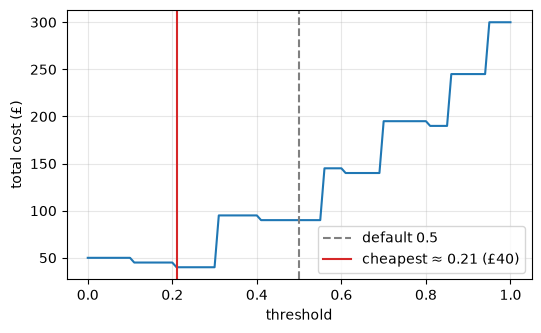

cost at 0.5: £90   at everyone (t=0): £50   cheapest: £40


In [6]:
ts = np.linspace(0, 1, 101)
costs = [cost(ten["y"], ten["p"], t) for t in ts]
best = ts[int(np.argmin(costs))]
plt.figure(figsize=(6, 3.5))
plt.plot(ts, costs); plt.axvline(0.5, ls="--", color="gray", label="default 0.5")
plt.axvline(best, color="tab:red", label=f"cheapest ≈ {best:.2f} (£{min(costs)})")
plt.xlabel("threshold"); plt.ylabel("total cost (£)"); plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"cost at 0.5: £{cost(ten['y'], ten['p'], 0.5)}   at everyone (t=0): £{cost(ten['y'], ten['p'], 0.0)}   cheapest: £{min(costs)}")

Any threshold between 0.21 and 0.30 flags exactly A–H and costs £40, the minimum. The default 0.5 costs £90; vouchers for everyone cost £50.

## 6. On the real ShopWave customers

Same table as 03.6, same logistic regression. Now choose its threshold properly.

> **About `train_test_split`.** We hold back 25% of customers and score the model only on those, because scoring a model on the rows it learned from is like marking your own homework. Module 04 explains this properly; for now, just know that `X_test` / `y_test` are "exam" customers the model never saw.

In [7]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd, numpy as np
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

xlsx = ensure_online_retail()
csv = xlsx.with_name("online_retail_2010_2011.csv")          # fast cache written by lesson 01.3
raw = pd.read_csv(csv, parse_dates=["InvoiceDate"]) if csv.exists() else pd.read_excel(xlsx, sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


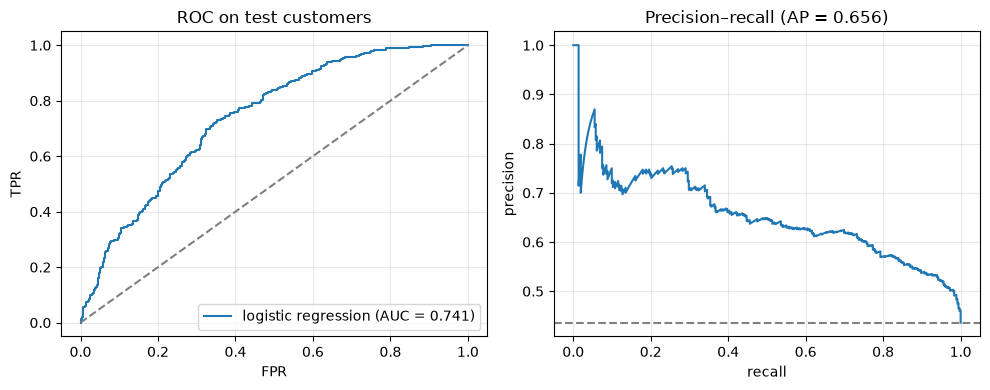

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)
proba_test = logreg.predict_proba(X_test)[:, 1]          # P(churn) for each test customer
pred_test = logreg.predict(X_test)                        # same as (proba_test >= 0.5)

auc = roc_auc_score(y_test, proba_test)
fpr, tpr, _ = roc_curve(y_test, proba_test)
prec, rec, _ = precision_recall_curve(y_test, proba_test)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(fpr, tpr, label=f"logistic regression (AUC = {auc:.3f})"); ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set(xlabel="FPR", ylabel="TPR", title="ROC on test customers"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(rec, prec); ax[1].axhline(y_test.mean(), ls="--", color="gray")
ax[1].set(xlabel="recall", ylabel="precision", title=f"Precision–recall (AP = {average_precision_score(y_test, proba_test):.3f})"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

AUC 0.741
cost at default 0.5:        £9,410
cost sending to everyone:   £4,150
cost sending to nobody:     £21,720
cheapest threshold 0.14: £3,875


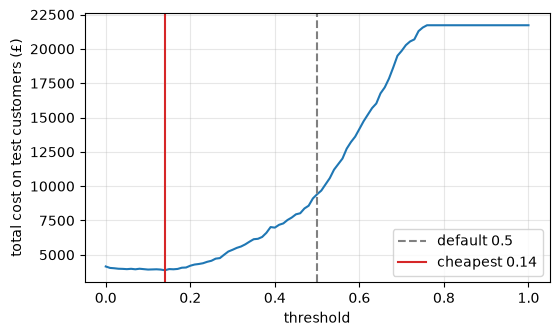

In [9]:
ts = np.linspace(0, 1, 101)
costs = np.array([cost(y_test, proba_test, t) for t in ts])
best_t = ts[costs.argmin()]
print(f"AUC {auc:.3f}")
print(f"cost at default 0.5:        £{cost(y_test, proba_test, 0.5):,}")
print(f"cost sending to everyone:   £{cost(y_test, proba_test, 0.0):,}")
print(f"cost sending to nobody:     £{cost(y_test, proba_test, 1.01):,}")
print(f"cheapest threshold {best_t:.2f}: £{costs.min():,}")

plt.figure(figsize=(6, 3.5))
plt.plot(ts, costs); plt.axvline(0.5, ls="--", color="gray", label="default 0.5")
plt.axvline(best_t, color="tab:red", label=f"cheapest {best_t:.2f}")
plt.xlabel("threshold"); plt.ylabel("total cost on test customers (£)"); plt.legend(); plt.grid(alpha=.3); plt.show()

Read the printed lines. The cheapest threshold is well below 0.5, because a missed churner costs twelve vouchers. Note also where "send to everyone" lands: when vouchers are cheap and churn is common, the model has to beat *that*, not "send to nobody".

### What if a lost customer is worth more?

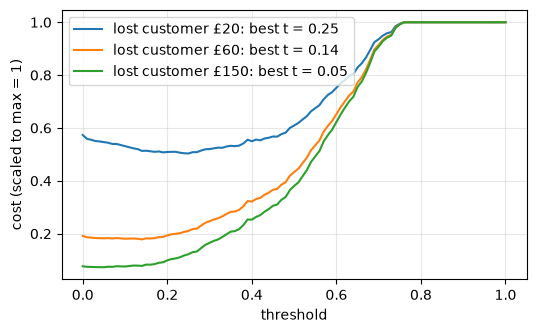

In [10]:
plt.figure(figsize=(6, 3.5))
for c_lost in [20, 60, 150]:
    cs = np.array([cost(y_test, proba_test, t, c_lost=c_lost) for t in ts])
    plt.plot(ts, cs / cs.max(), label=f"lost customer £{c_lost}: best t = {ts[cs.argmin()]:.2f}")
plt.xlabel("threshold"); plt.ylabel("cost (scaled to max = 1)"); plt.legend(); plt.grid(alpha=.3); plt.show()

The more a lost customer costs, the lower the best threshold: flag more people, accept more wasted vouchers. The model did not change; the business numbers did.

## Quiz answers

1. True positive rate (recall) on the y-axis against false positive rate on the x-axis, one point per threshold.
2. It ranks positives and negatives no better than chance; its scores carry no information.
3. AUC measures ranking over *all* thresholds. At any one threshold the two models may flag different numbers of customers, so precision (and recall) differ.
4. When positives are rare: FPR stays tiny even with many false alarms, so ROC looks fine while precision collapses. Precision–recall shows the collapse.
5. That a false positive and a false negative cost the same. If they do not, the cheapest threshold is somewhere else.

**Next:** [03.8 Multi-class classification](../08-multiclass/)